# 五类花卉识别实验

在 JupyterLab 打开本文件，从上到下用 **Shift + Enter** 逐格运行。每个代码单元完成一个步骤，中间结果会留在当前内核。遇到变量未定义时，先执行其上方的单元。

本 Notebook 调用项目原有的 PyTorch 模块。已有实验记录可以直接查看，图片预处理、单图预测和重新评估需要花卉数据或自己的图片。最后一节可以选择从头训练，使用新建的运行目录。

[实验报告](实验报告/花卉识别实验报告.md) · [项目 README](README.md) · [样例图片署名](runs/plateau/figures/IMAGE_CREDITS.txt)

预处理显示的雏菊原图来自 [mario](https://www.flickr.com/photos/64738468@N00/100080576/)，单图识别默认展示的测试照片来自 [Sarah Zucca](https://www.flickr.com/photos/livetocreate_photography/10172379554/)，均按 [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/) 使用。

## 1. 初始化与数据路径

先确认内核可以导入项目依赖。新环境可以在终端执行 `python -m pip install -r requirements.txt jupyterlab`，然后从项目根目录运行 `python -m jupyterlab`。桌面上的项目副本会尝试读取原课件目录中的数据，也可以在下面指定自己的数据路径。

In [1]:
from collections import Counter
from pathlib import Path
from html import escape
import json
import shutil
import tempfile

import torch
from PIL import Image as PILImage, ImageOps
from IPython.display import HTML, Image, display

from compare_runs import read_csv, review
from data import CLASSES
from evaluation import evaluate
from inference import load_model, predict
from main import SEED, prepare
from model import FlowerCNN
from preprocess import FlowerDataset, center_crop, load_image, resize
from training import smoke_check, train

ROOT = Path.cwd()
assert (ROOT / "runs" / "plateau" / "best.pt").is_file(), "请从项目根目录启动 Notebook。"
BASELINE = ROOT / "runs" / "formal"
OPTIMIZED = ROOT / "runs" / "plateau"
CLASS_NAMES = dict(zip(CLASSES, ("雏菊", "蒲公英", "玫瑰", "向日葵", "郁金香")))

DATA_DIR = ROOT / "flower_data"
if not DATA_DIR.is_dir():
    DATA_DIR = ROOT.parent / "人工智能原理课件" / "04-实验与作业" / "flower" / "flower_data"
HAS_DATA = all((DATA_DIR / split).is_dir() for split in ("train", "val"))
IMAGE_PATH = None  # 可设为 Path("/你的图片路径.jpg")

def show_table(headers, rows):
    head = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

print(f"PyTorch {torch.__version__}，MPS {'可用' if torch.backends.mps.is_available() else '不可用'}")
print("已找到课程数据集。" if HAS_DATA else "可以查看已保存的实验结果。配置 DATA_DIR 后可运行实图单元。")

PyTorch 2.15.0，MPS 可用
已找到课程数据集。


## 2. 查看数据清单

清单中的 `source_split` 记录原始存放位置，`split` 记录实验用途。先按文件哈希去重，再从原训练集按类别抽取约 15% 作为测试集，最后分别检查三组的样本数。

In [2]:
manifest = read_csv(OPTIMIZED / "manifest.csv")
excluded = read_csv(OPTIMIZED / "excluded.csv")
splits = ("train", "val", "test")
counts = Counter((row["class_name"], row["split"]) for row in manifest)
show_table(
    ["类别", "训练集", "验证集", "测试集"],
    [[CLASS_NAMES[name], *(counts[name, group] for group in splits)] for name in CLASSES]
    + [["合计", *(sum(counts[name, group] for name in CLASSES) for group in splits)]],
)
print(f"去重及标签冲突处理共排除 {len(excluded)} 条记录。")
assert len({row["sha256"] for row in manifest}) == len(manifest)

类别,训练集,验证集,测试集
雏菊,438,117,77
蒲公英,660,121,116
玫瑰,456,103,80
向日葵,509,97,90
郁金香,587,107,104
合计,2650,545,467


去重及标签冲突处理共排除 4 条记录。


## 3. 从图片到输入张量

用清单中的第一张训练图观察等比例缩放和中心裁剪。最终输入包含 3 个颜色通道，像素值缩放到 0–1。

原图 (320, 263) → 缩放 (155, 128) → 裁剪 (128, 128)


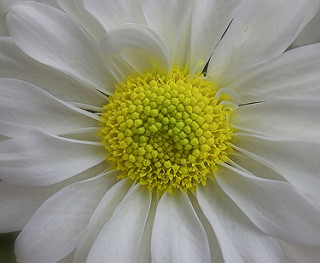

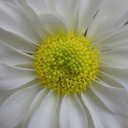

形状 (3, 128, 128)，值域 [0.008, 0.788]
标签 0 · 雏菊


In [3]:
if HAS_DATA:
    dataset = FlowerDataset("train", DATA_DIR, OPTIMIZED / "manifest.csv")
    path = DATA_DIR / dataset.rows[0]["path"]
    tensor, label = dataset[0]
    with PILImage.open(path) as source:
        rgb = ImageOps.exif_transpose(source).convert("RGB")
        resized = resize(rgb)
        cropped = center_crop(resized)
        print(f"原图 {rgb.size} → 缩放 {resized.size} → 裁剪 {cropped.size}")
        display(Image(filename=str(path), width=240), cropped)
    print(f"形状 {tuple(tensor.shape)}，值域 [{tensor.min():.3f}, {tensor.max():.3f}]")
    print(f"标签 {label} · {CLASS_NAMES[CLASSES[label]]}")
else:
    print("找到原始图片后，可在这里查看预处理的前后变化。")

## 4. 搭建 CNN 与检查前向传播

先用一批形状已知的空张量检查网络各阶段的输出。四个卷积块逐步减少空间尺寸，全局平均池化得到 256 个特征，最后映射为五个类别分数。

In [4]:
network = FlowerCNN().eval()
stages = []
with torch.inference_mode():
    features = torch.zeros(1, 3, 128, 128)
    stages.append(("RGB 输入", tuple(features.shape)))
    for index, block in enumerate(network.features, start=1):
        features = block(features)
        stages.append((f"卷积块 {index}", tuple(features.shape)))
    features = network.flatten(network.pool(features))
    stages.append(("全局平均池化与展平", tuple(features.shape)))
    logits = network.classifier(network.dropout(features))
    stages.append(("线性分类层", tuple(logits.shape)))
show_table(["阶段", "批次输出形状"], stages)
print(f"可训练参数 {sum(p.numel() for p in network.parameters() if p.requires_grad):,} 个")

阶段,批次输出形状
RGB 输入,"(1, 3, 128, 128)"
卷积块 1,"(1, 32, 64, 64)"
卷积块 2,"(1, 64, 32, 32)"
卷积块 3,"(1, 128, 16, 16)"
卷积块 4,"(1, 256, 8, 8)"
全局平均池化与展平,"(1, 256)"
线性分类层,"(1, 5)"


可训练参数 390,181 个


## 5. 用小批量理解模型训练

项目的 `smoke_check()` 用 8 张训练图完成一次交叉熵与 Adam 更新，再检查权重能否保存和恢复。它使用临时模型，适合在开始 25 轮训练前先检查运行环境。

In [5]:
if HAS_DATA:
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    torch.manual_seed(SEED)
    check = smoke_check(dataset, device, torch.nn.CrossEntropyLoss())
    print(f"批量 {check['batch_size']}，本批损失 {check['loss']:.4f}")
    print(f"分类层权重最大变化 {check['max_weight_change']:.6f}")
    print(f"重新加载后预测一致：{check['reload_prediction_matches']}")
else:
    print("原实验的小批量检查记录：")
    display(json.loads((OPTIMIZED / "smoke.json").read_text()))

批量 8，本批损失 1.6478
分类层权重最大变化 0.001000
重新加载后预测一致：True


## 6. 对照学习率与训练记录

`history.csv` 保存了 25 轮的损失和准确率。这里找出每组验证损失最低的一轮，并用图观察优化组的学习率从第 14、20 轮起分别减半。

训练组,训练轮数,选用轮次,验证损失,该轮验证准确率
固定学习率,25,22,0.6578,77.61%
动态学习率,25,24,0.5655,79.45%


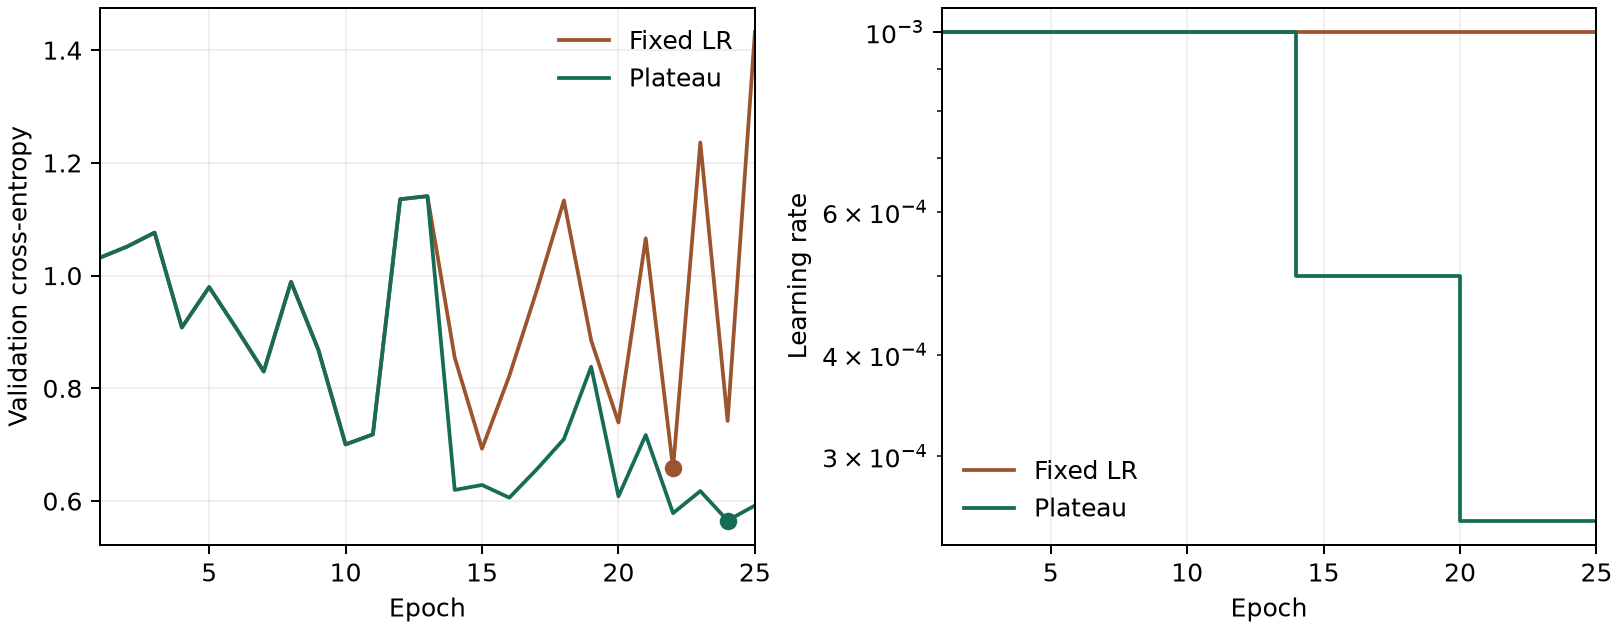

In [6]:
history_table = []
for label, path in [("固定学习率", BASELINE), ("动态学习率", OPTIMIZED)]:
    history = read_csv(path / "history.csv")
    best = min(history, key=lambda row: float(row["val_loss"]))
    history_table.append([
        label, len(history), best["epoch"], f"{float(best['val_loss']):.4f}",
        f"{float(best['val_accuracy']):.2%}",
    ])
show_table(["训练组", "训练轮数", "选用轮次", "验证损失", "该轮验证准确率"], history_table)
display(Image(filename=str(OPTIMIZED / "comparison.png"), width=810))

## 7. 查看整组测试结果

`review()` 核对每张图的预测、混淆矩阵、准确率和宏平均 F1。矩阵的行是真实类别，列是预测类别。

训练组,选用轮次,测试正确数,准确率,宏平均 F1
固定学习率,22,358/467,76.66%,0.7691
动态学习率,24,378/467,80.94%,0.8081


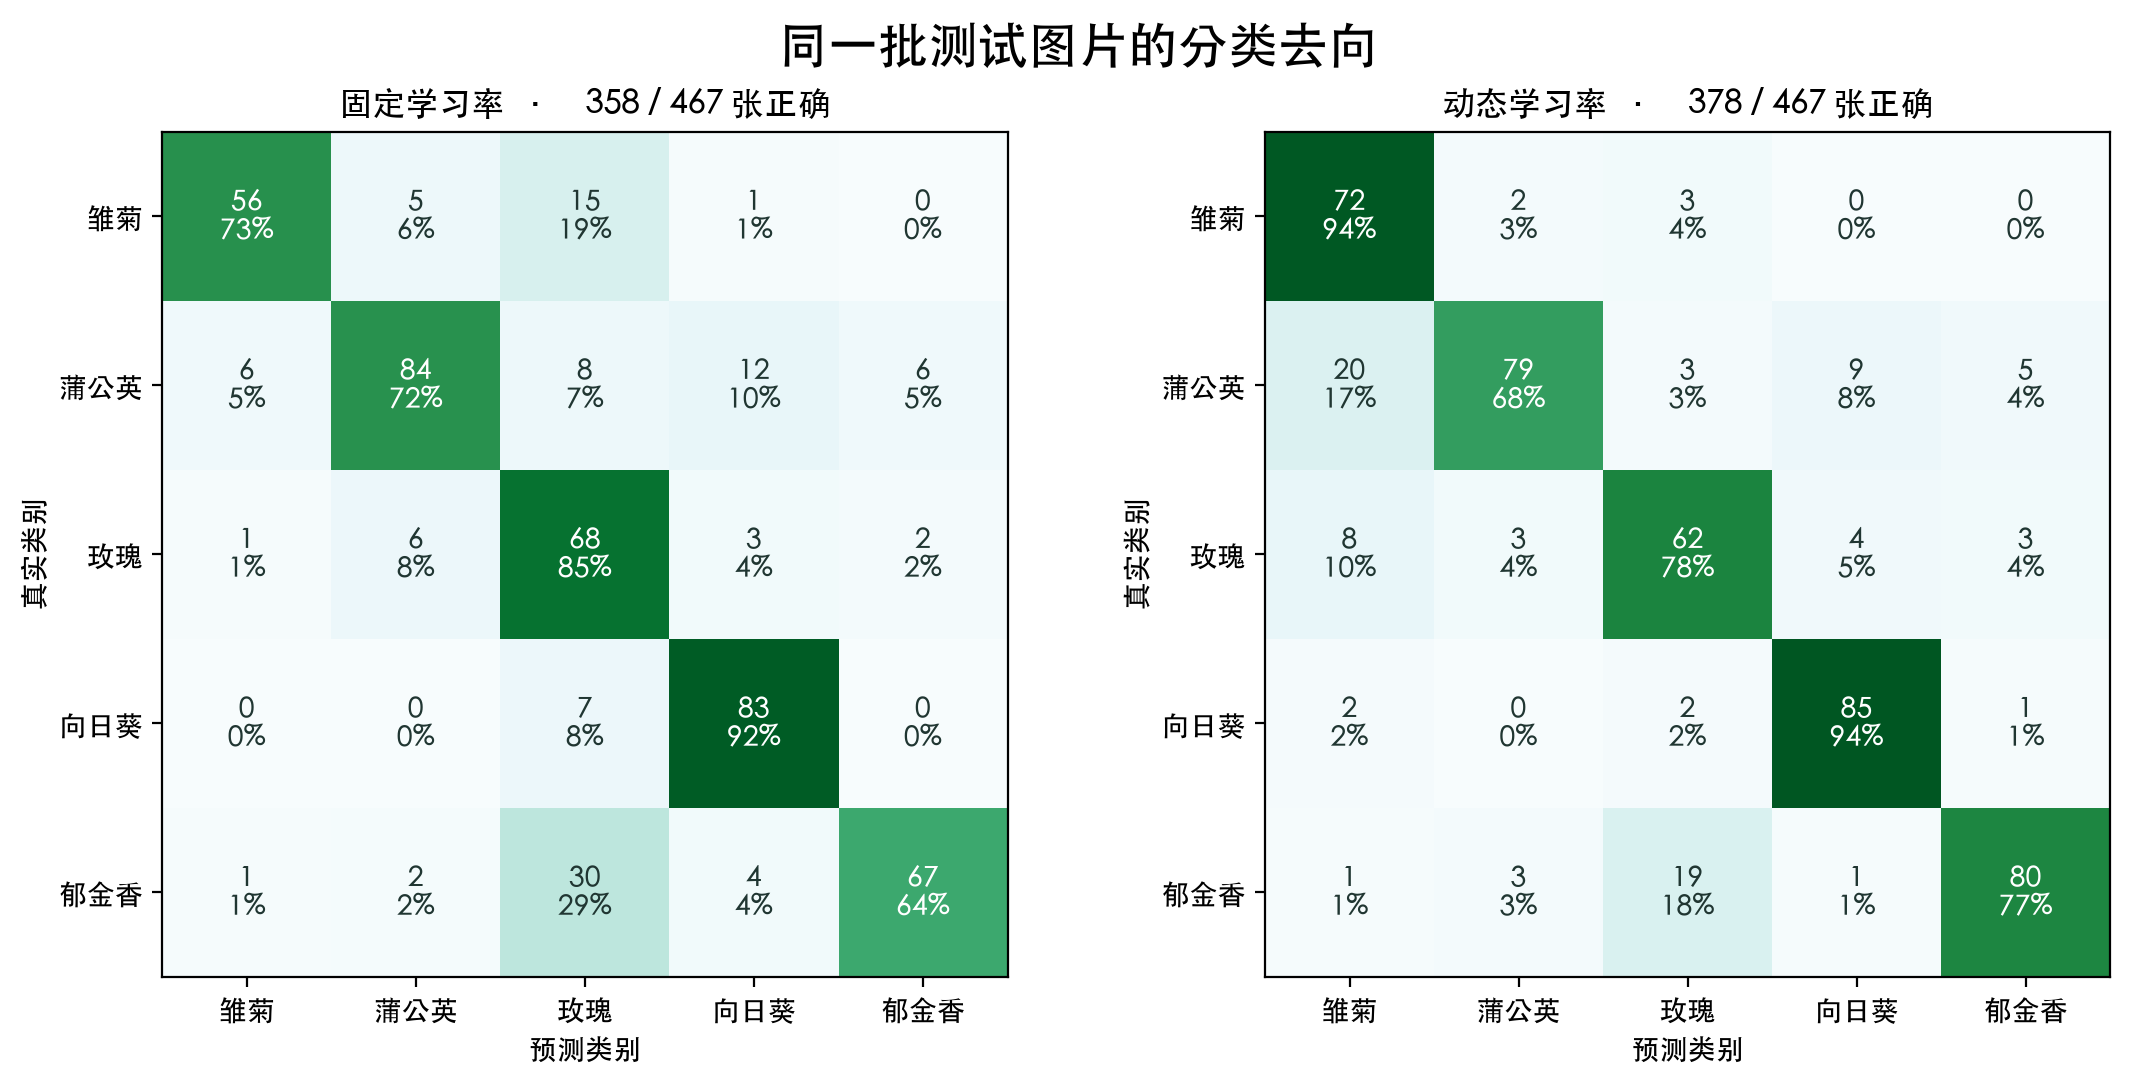

In [7]:
result_rows = []
for label, run in [("固定学习率", BASELINE), ("动态学习率", OPTIMIZED)]:
    _, _, metrics, _ = review(run)
    result_rows.append([
        label, metrics["epoch"], f"{metrics['correct']}/{metrics['total']}",
        f"{metrics['accuracy']:.2%}", f"{metrics['macro_f1']:.4f}",
    ])
show_table(["训练组", "选用轮次", "测试正确数", "准确率", "宏平均 F1"], result_rows)
display(Image(filename=str(OPTIMIZED / "figures" / "01_confusion.png"), width=850))

## 8. 加载最佳权重，识别一张图片

默认展示测试清单中的第一张图，也可以在第 1 节指定 `IMAGE_PATH`。模型输出五类概率，最大值对应预测类别。

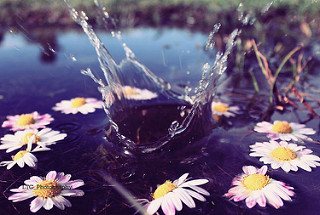

权重来自第 24 轮，预测为雏菊。


类别,概率
雏菊,97.35%
蒲公英,0.34%
玫瑰,1.59%
向日葵,0.60%
郁金香,0.13%


In [8]:
sample_path = IMAGE_PATH
if sample_path is None and HAS_DATA:
    row = next(row for row in manifest if row["split"] == "test")
    sample_path = DATA_DIR / row["path"]

if sample_path is not None:
    model, epoch = load_model(OPTIMIZED)
    scores = predict(model, sample_path)
    display(Image(filename=str(sample_path), width=260))
    print(f"权重来自第 {epoch} 轮，预测为{CLASS_NAMES[max(scores, key=scores.get)]}。")
    show_table(["类别", "概率"], [(CLASS_NAMES[k], f"{v:.2%}") for k, v in scores.items()])
else:
    print("设定 IMAGE_PATH 后可以预测自己的图片。下面是已保存的测试样例。")
    display(Image(filename=str(OPTIMIZED / "figures" / "03_predictions.png"), width=900))

## 9. 用已保存的权重重新评估

有数据集时，调用原有的 `evaluate()` 在 CPU 上跑完整测试集。把权重和清单复制到临时目录，重新生成的逐图预测和指标也写入那里。

In [9]:
if HAS_DATA:
    with tempfile.TemporaryDirectory(prefix="flower-notebook-eval-") as directory:
        replay = Path(directory)
        for filename in ("manifest.csv", "best.pt"):
            shutil.copy2(OPTIMIZED / filename, replay / filename)
        evaluate(DATA_DIR, replay)
        fresh = json.loads((replay / "test_metrics.json").read_text())
    saved = json.loads((OPTIMIZED / "test_metrics.json").read_text())
    print("混淆矩阵与已保存结果一致：" + str(fresh["confusion_matrix"] == saved["confusion_matrix"]))
else:
    print("配置课程数据目录后，可运行本单元重新评估。")

正确 378/467，准确率 80.94%，宏平均 F1 0.8081
tensor([[72,  2,  3,  0,  0],
        [20, 79,  3,  9,  5],
        [ 8,  3, 62,  4,  3],
        [ 2,  0,  2, 85,  1],
        [ 1,  3, 19,  1, 80]])
混淆矩阵与已保存结果一致：True


## 10. 可选 · 从随机初始化开始训练

设置 `RUN_TRAINING = True` 后运行下方单元即可开始正式训练。每次运行会在 `runs/` 下新建一个目录，并依次写入清单、25 轮日志、权重和测试结果。将 `SCHEDULE` 设为 `constant` 可以运行固定学习率组。

In [10]:
RUN_TRAINING = False
SCHEDULE = "plateau"

if RUN_TRAINING:
    if not HAS_DATA:
        raise FileNotFoundError("请先在第 1 节设置包含 train 和 val 的 DATA_DIR。")
    new_run = Path(tempfile.mkdtemp(prefix="notebook-", dir=ROOT / "runs"))
    prepare(DATA_DIR, new_run)
    train(DATA_DIR, new_run, SEED, lr_schedule=SCHEDULE)
    evaluate(DATA_DIR, new_run)
    print(f"本次实验记录：{new_run.relative_to(ROOT)}")
else:
    print("从头训练当前关闭。")

从头训练当前关闭。
